In [25]:
%pip install pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [26]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv('imageset_gray_100_75.csv')
print(df.shape)

(1384, 7501)


(np.float64(-0.5), np.float64(99.5), np.float64(74.5), np.float64(-0.5))

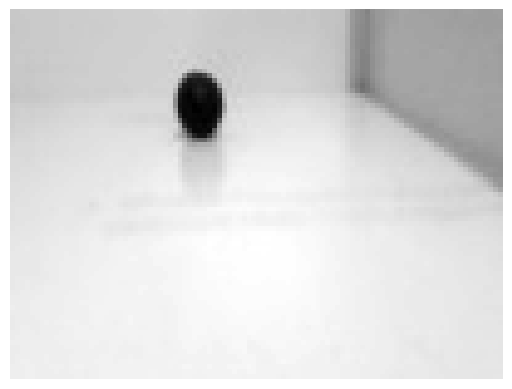

In [27]:
import numpy as np
some_image = df.loc[10,df.columns[:-1]] # type: ignore
some_image_np = some_image.to_numpy()

plt.imshow(np.reshape(some_image_np, (75,100)), cmap='gray')
plt.axis('off')

In [28]:
# problema binario
#X = df.loc[df['y'].isin([0, 1]),:]
#X = X.drop(columns={'y'})
#y = df.loc[df['y'].isin([0, 1]),'y']

#problema multiclasse
X = df.drop(columns={'y'})
y = df['y']


In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40, stratify=y)

In [30]:
print(y_train.value_counts())
print(y_test.value_counts())

y
2    369
1    369
0    369
Name: count, dtype: int64
y
2    93
0    92
1    92
Name: count, dtype: int64


### Usando os 5 modelos também com o SGD

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# 1. Definir os 5 modelos
models = {
    "SGDClassifier": SGDClassifier(random_state=42, loss='hinge', penalty='l2'),
    "LogisticRegression": LogisticRegression(random_state=42, max_iter=1000),
    "LinearSVC": LinearSVC(random_state=42, dual=False),
    "RandomForest": RandomForestClassifier(random_state=42, n_estimators=100),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# 2. Validação Cruzada Estratificada com 5 Folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
print("Iniciando Validação Cruzada dos 5 Modelos...\n")

for name, model in models.items():
    # Avalia com acurácia média nos 5 folds de treino
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    results[name] = {
        "Acurácia Média": scores.mean(),
        "Desvio Padrão": scores.std(),
        "Scores": scores
    }
    print(f"{name:20s} -> Acurácia Média: {scores.mean():.4f} (+/- {scores.std():.4f})")

Iniciando Validação Cruzada dos 5 Modelos...

SGDClassifier        -> Acurácia Média: 0.6686 (+/- 0.0754)
LogisticRegression   -> Acurácia Média: 0.8455 (+/- 0.0193)
LinearSVC            -> Acurácia Média: 0.8193 (+/- 0.0173)
RandomForest         -> Acurácia Média: 0.9431 (+/- 0.0214)
KNN                  -> Acurácia Média: 0.7985 (+/- 0.0085)


### Escolhendo o melhor modelo

In [32]:
# Criar DataFrame com o resumo comparativo
df_results = pd.DataFrame([
    {"Modelo": name, "Acurácia Média": res["Acurácia Média"], "Desvio Padrão": res["Desvio Padrão"]}
    for name, res in results.items()
]).sort_values(by="Acurácia Média", ascending=False).reset_index(drop=True)

print("\n--- Ranking dos Modelos ---")
print(df_results)

# Selecionar o melhor nome de modelo
best_model_name = df_results.iloc[0]["Modelo"]
print(f"\n=> Melhor modelo selecionado: {best_model_name} com acurácia de {df_results.iloc[0]['Acurácia Média']:.4f}")


--- Ranking dos Modelos ---
               Modelo  Acurácia Média  Desvio Padrão
0        RandomForest        0.943125       0.021402
1  LogisticRegression        0.845526       0.019297
2           LinearSVC        0.819322       0.017250
3                 KNN        0.798549       0.008515
4       SGDClassifier        0.668579       0.075357

=> Melhor modelo selecionado: RandomForest com acurácia de 0.9431


### Aplicando o Grid Search no melhor modelo

Fitting 5 folds for each of 12 candidates, totalling 60 fits



Melhores Hiperparâmetros (RandomForest): {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Melhor score de validação cruzada: 0.9359

--- Relatório Final no Conjunto de Teste ---
                  precision    recall  f1-score   support

Vítima Morta (0)       0.97      0.93      0.95        92
 Vítima Viva (1)       0.89      0.97      0.93        92
  Sem Vítima (2)       1.00      0.95      0.97        93

        accuracy                           0.95       277
       macro avg       0.95      0.95      0.95       277
    weighted avg       0.95      0.95      0.95       277


Modelo otimizado salvo em 'melhor_modelo_otimizado.pkl'


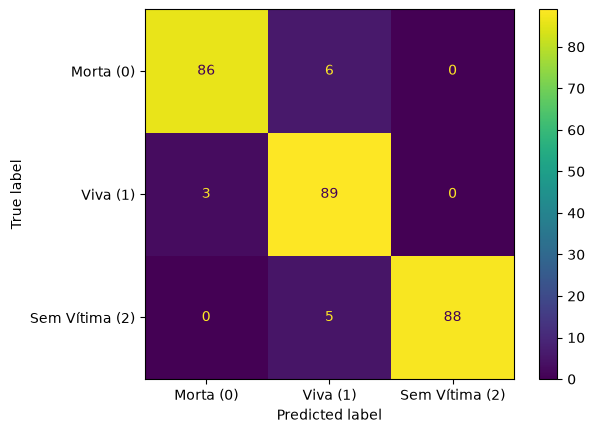

In [33]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import pickle

# Definir as grades de parâmetros para cada candidato possível
param_grids = {
    "SGDClassifier": {
        'loss': ['hinge', 'log_loss', 'modified_huber'],
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': [1e-5, 1e-4, 1e-3, 1e-2],
        'max_iter': [1000, 2000]
    },
    "LogisticRegression": {
        'C': [0.01, 0.1, 1.0, 10.0],
        'penalty': ['l2'],
        'solver': ['lbfgs']
    },
    "LinearSVC": {
        'C': [0.01, 0.1, 1.0, 10.0],
        'loss': ['squared_hinge'],
        'dual': [False]
    },
    "RandomForest": {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    },
    "KNN": {
        'n_neighbors': [3, 5, 7, 9],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }
}

# 1. Configurar o GridSearchCV para o modelo vencedor
grid_search = GridSearchCV(
    estimator=models[best_model_name],
    param_grid=param_grids[best_model_name],
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

# 2. Executar o Grid Search no treino
grid_search.fit(X_train, y_train)

print(f"\nMelhores Hiperparâmetros ({best_model_name}):", grid_search.best_params_)
print(f"Melhor score de validação cruzada: {grid_search.best_score_:.4f}")

# 3. Avaliação no conjunto de Teste (dados nunca vistos)
best_tuned_model = grid_search.best_estimator_
y_test_pred = best_tuned_model.predict(X_test)

print("\n--- Relatório Final no Conjunto de Teste ---")
print(classification_report(y_test, y_test_pred, target_names=['Vítima Morta (0)', 'Vítima Viva (1)', 'Sem Vítima (2)']))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Morta (0)', 'Viva (1)', 'Sem Vítima (2)'])
disp.plot()

# 4. Salvar o modelo final otimizado
with open('melhor_modelo_otimizado.pkl', 'wb') as f:
    pickle.dump(best_tuned_model, f)
print("\nModelo otimizado salvo em 'melhor_modelo_otimizado.pkl'")